# Практическое задание: Нейросети в PyTorch (MLP)

В этом задании вы построите полносвязную нейронную сеть для задачи бинарной классификации.
Мы будем использовать классический датасет Breast Cancer (предсказание характера опухоли).

**Задача:**
1. Дописать класс Dataset.
2. Создать архитектуру сети.
3. Написать циклы обучения и валидации.
4. Обучить базовую модель.
5. Провести эксперименты по улучшению качества.

> **Решение.** Заполнены все места `# ВАШ КОД ЗДЕСЬ`, обучена базовая модель и проведены
> три эксперимента: (1) более глубокая и широкая сеть, (2) BatchNorm + Dropout + weight decay,
> (3) оптимизатор SGD с импульсом. Все графики сохраняются в папку `reports/`.

In [1]:
import json
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Зафиксируем seed для воспроизводимости
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()

REPORTS = Path("reports")
REPORTS.mkdir(exist_ok=True)

print("torch:", torch.__version__)

torch: 2.15.0+cpu


## 1. Подготовка данных

Данные уже загружены, разделены на обучающую и тестовую выборки, а также стандартизированы.

In [2]:
# Загрузка данных
data = load_breast_cancer()
X = data.data
y = data.target

# Разделение на train и test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Стандартизация (очень важна для нейросетей)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Размерность X_train: {X_train.shape}")
print(f"Размерность X_test: {X_test.shape}")
print(f"Доля класса 1 (злокачественная) в train: {y_train.mean():.3f}")

Размерность X_train: (455, 30)
Размерность X_test: (114, 30)
Доля класса 1 (злокачественная) в train: 0.629


### Создание PyTorch Dataset

PyTorch работает с данными через абстракции `Dataset` и `DataLoader`.

In [3]:
class CancerDataset(Dataset):
    def __init__(self, X, y):
        # Переводим в тензоры сразу при инициализации
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Создаем экземпляры Dataset
train_dataset = CancerDataset(X_train, y_train)
test_dataset = CancerDataset(X_test, y_test)

# DataLoader для train: batch_size=32, перемешивание нужно для стохастического обучения
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# DataLoader для test: без перемешивания, чтобы порядок был стабильным
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Батчей в train: {len(train_loader)}, в test: {len(test_loader)}")
batch_X, batch_y = next(iter(train_loader))
print("Форма батча X:", tuple(batch_X.shape), "| форма батча y:", tuple(batch_y.shape))

Батчей в train: 15, в test: 4
Форма батча X: (32, 30) | форма батча y: (32, 1)


## 2. Архитектура нейронной сети

**Задание:** Напишите класс нейронной сети.
- Входной слой должен принимать количество признаков (у нас их 30).
- Сделайте 1 или 2 скрытых слоя.
- Выходной слой должен выдавать 1 число (вероятность или логит для бинарной классификации).
- Используйте функции активации (например, ReLU).

In [4]:
class BinaryClassificationMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super(BinaryClassificationMLP, self).__init__()
        # Один скрытый слой: input_dim -> hidden_dim -> 1
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc_out = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # прямой проход: линейный слой -> ReLU -> выходной логит
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc_out(x)
        return x

# Инициализация модели
set_seed()
input_size = X_train.shape[1]
model = BinaryClassificationMLP(input_dim=input_size)
print(model)
print("Обучаемых параметров:", sum(p.numel() for p in model.parameters()))

BinaryClassificationMLP(
  (fc1): Linear(in_features=30, out_features=16, bias=True)
  (relu): ReLU()
  (fc_out): Linear(in_features=16, out_features=1, bias=True)
)
Обучаемых параметров: 513


## 3. Функция потерь и оптимизатор

Для бинарной классификации стандартным выбором является Binary Cross Entropy.
В PyTorch это `nn.BCEWithLogitsLoss()` (если на выходе сети нет сигмоиды) или `nn.BCELoss()`
(если сигмоида есть). В нашей сети на выходе **логиты** (без сигмоиды), поэтому берём
`BCEWithLogitsLoss` — она численно устойчивее, чем `Sigmoid` + `BCELoss`.

In [5]:
# BCEWithLogitsLoss сама применяет сигмоиду внутри и считает BCE стабильно
criterion = nn.BCEWithLogitsLoss()

# Adam — стандартный выбор для старта: адаптивный шаг, быстро сходится
optimizer = optim.Adam(model.parameters(), lr=1e-3)

print(criterion)
print(optimizer)

BCEWithLogitsLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 4. Цикл обучения (Training Loop)

Цикл обучения:
1. Проходит по эпохам.
2. Проходит по батчам обучающей выборки.
3. Делает прямой проход, считает loss, считает градиенты и делает шаг оптимизатора.
4. В конце каждой эпохи прогоняет валидационную выборку (без подсчёта градиентов!) для оценки метрик.

In [6]:
epochs = 50
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(epochs):
    # --- ОБУЧЕНИЕ ---
    model.train()  # Переводим модель в режим обучения
    epoch_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_X, batch_y in train_loader:
        # 1. Обнуляем градиенты предыдущего шага
        optimizer.zero_grad()
        # 2. Прямой проход
        outputs = model(batch_X)
        # 3. Считаем ошибку
        loss = criterion(outputs, batch_y)
        # 4. Обратное распространение ошибки
        loss.backward()
        # 5. Шаг оптимизатора
        optimizer.step()

        epoch_train_loss += loss.item()
        preds = (torch.sigmoid(outputs) >= 0.5).float()
        train_correct += (preds == batch_y).sum().item()
        train_total += batch_y.size(0)

    avg_train_loss = epoch_train_loss / len(train_loader)
    train_acc = train_correct / train_total
    train_losses.append(avg_train_loss)
    train_accuracies.append(train_acc)

    # --- ВАЛИДАЦИЯ ---
    model.eval()  # Отключает dropout/batchnorm в режиме оценки
    epoch_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():  # Отключаем вычисление градиентов
        for batch_X, batch_y in test_loader:
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            epoch_val_loss += loss.item()

            preds = (torch.sigmoid(outputs) >= 0.5).float()
            val_correct += (preds == batch_y).sum().item()
            val_total += batch_y.size(0)

    avg_val_loss = epoch_val_loss / len(test_loader)
    val_acc = val_correct / val_total
    val_losses.append(avg_val_loss)
    val_accuracies.append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(f"Эпоха {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

print(f"\nИтог: train acc = {train_accuracies[-1]:.4f}, val acc = {val_accuracies[-1]:.4f}")

Эпоха 10/50 | Train Loss: 0.1932 | Val Loss: 0.1483 | Train Acc: 0.9429 | Val Acc: 0.9737


Эпоха 20/50 | Train Loss: 0.0951 | Val Loss: 0.0796 | Train Acc: 0.9846 | Val Acc: 0.9737
Эпоха 30/50 | Train Loss: 0.0666 | Val Loss: 0.0632 | Train Acc: 0.9868 | Val Acc: 0.9825


Эпоха 40/50 | Train Loss: 0.0724 | Val Loss: 0.0546 | Train Acc: 0.9846 | Val Acc: 0.9912


Эпоха 50/50 | Train Loss: 0.0647 | Val Loss: 0.0529 | Train Acc: 0.9846 | Val Acc: 0.9912

Итог: train acc = 0.9846, val acc = 0.9912


## 5. Графики обучения

Визуализация помогает понять, учится ли модель и нет ли переобучения.
Строим две кривые: loss и accuracy — для train и validation.

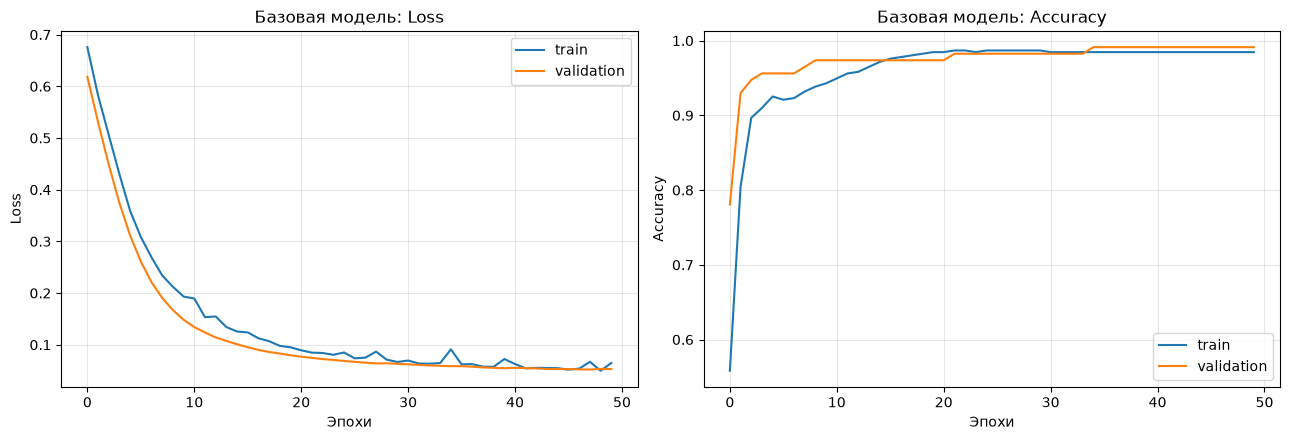

Разрыв train/val accuracy в конце обучения: -0.0066


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(train_losses, label="train")
axes[0].plot(val_losses, label="validation")
axes[0].set_title("Базовая модель: Loss")
axes[0].set_xlabel("Эпохи")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(train_accuracies, label="train")
axes[1].plot(val_accuracies, label="validation")
axes[1].set_title("Базовая модель: Accuracy")
axes[1].set_xlabel("Эпохи")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(REPORTS / "baseline_curves.png", dpi=130, bbox_inches="tight")
plt.show()

gap = train_accuracies[-1] - val_accuracies[-1]
print(f"Разрыв train/val accuracy в конце обучения: {gap:+.4f}")

## 6. Эксперименты по улучшению модели

Ниже — три эксперимента. Для каждого заново фиксируется seed, архитектура и оптимизатор,
затем обучение идёт тем же циклом (вынесен в функцию `fit`), а результаты складываются
в сводную таблицу.

**Эксперимент 1. Глубже и шире.** Базовая сеть имеет один скрытый слой на 16 нейронов.
Добавим второй скрытый слой и увеличим ширину: 30 → 64 → 32 → 1. Гипотеза: больше
параметров — лучше разделяющая поверхность.

**Эксперимент 2. Регуляризация.** Та же широкая архитектура, но с `BatchNorm1d`,
`Dropout(0.3)` и `weight_decay=1e-4`, learning rate снижен до 5e-4, обучение 100 эпох.
Гипотеза: BatchNorm стабилизирует обучение, Dropout и L2-штраф борются с переобучением.

**Эксперимент 3. Другой оптимизатор.** Широкая архитектура без регуляризации, но
оптимизатор SGD с импульсом 0.9 и lr=0.01 (100 эпох). Гипотеза: SGD с моментом может
дать более гладкую сходимость, чем Adam.

In [8]:
def fit(model, criterion, optimizer, train_loader, val_loader, epochs, seed=SEED):
    # Полный цикл обучения с логированием loss/accuracy по эпохам
    set_seed(seed)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            run_loss += loss.item()
            preds = (torch.sigmoid(outputs) >= 0.5).float()
            correct += (preds == batch_y).sum().item()
            total += batch_y.size(0)

        history["train_loss"].append(run_loss / len(train_loader))
        history["train_acc"].append(correct / total)

        model.eval()
        run_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)
                run_loss += loss.item()
                preds = (torch.sigmoid(outputs) >= 0.5).float()
                correct += (preds == batch_y).sum().item()
                total += batch_y.size(0)

        history["val_loss"].append(run_loss / len(val_loader))
        history["val_acc"].append(correct / total)

    return history


def collect_metrics(name, model, history):
    # Финальные метрики модели: accuracy, F1, переобучение, число параметров
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            outputs = model(batch_X)
            all_preds.append((torch.sigmoid(outputs) >= 0.5).int())
            all_targets.append(batch_y.int())
    preds = torch.cat(all_preds).squeeze().numpy()
    targets = torch.cat(all_targets).squeeze().numpy()

    return {
        "model": name,
        "params": sum(p.numel() for p in model.parameters()),
        "train_acc": round(history["train_acc"][-1], 4),
        "val_acc": round(history["val_acc"][-1], 4),
        "best_val_acc": round(max(history["val_acc"]), 4),
        "val_f1": round(f1_score(targets, preds), 4),
        "overfit_gap": round(history["train_acc"][-1] - history["val_acc"][-1], 4),
        "final_train_loss": round(history["train_loss"][-1], 4),
        "final_val_loss": round(history["val_loss"][-1], 4),
    }


def plot_history(history, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title}: Loss")
    axes[0].set_xlabel("Эпохи")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="validation")
    axes[1].set_title(f"{title}: Accuracy")
    axes[1].set_xlabel("Эпохи")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(REPORTS / filename, dpi=130, bbox_inches="tight")
    plt.show()


# базовая модель: сохраняем историю и метрики
baseline_history = {
    "train_loss": train_losses,
    "val_loss": val_losses,
    "train_acc": train_accuracies,
    "val_acc": val_accuracies,
}
results = [collect_metrics("Baseline (16, Adam)", model, baseline_history)]
pd.DataFrame(results)

,model,params,train_acc,val_acc,best_val_acc,val_f1,overfit_gap,final_train_loss,final_val_loss
0,"Baseline (16, Adam)",513,0.9846,0.9912,0.9912,0.993,-0.0066,0.0647,0.0529


### Эксперимент 1 — глубже и шире (30 → 64 → 32 → 1)

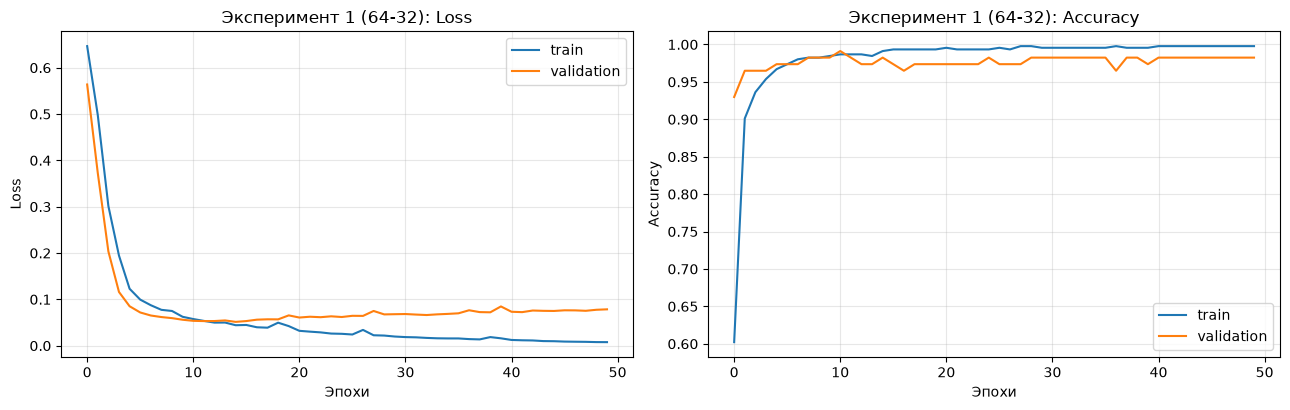

,model,params,train_acc,val_acc,best_val_acc,val_f1,overfit_gap,final_train_loss,final_val_loss
0,"Baseline (16, Adam)",513,0.9846,0.9912,0.9912,0.9930,-0.0066,0.0647,0.0529
1,"Exp1: 64-32, Adam",4097,0.9978,0.9825,0.9912,0.9859,0.0153,0.0077,0.0785


In [9]:
class DeepMLP(nn.Module):
    def __init__(self, input_dim, hidden_1=64, hidden_2=32):
        super(DeepMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden_1, hidden_2)
        self.relu2 = nn.ReLU()
        self.fc_out = nn.Linear(hidden_2, 1)

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc_out(x)

set_seed()
deep_model = DeepMLP(input_dim=input_size)
deep_criterion = nn.BCEWithLogitsLoss()
deep_optimizer = optim.Adam(deep_model.parameters(), lr=1e-3)

deep_history = fit(deep_model, deep_criterion, deep_optimizer, train_loader, test_loader, epochs=50)
plot_history(deep_history, "Эксперимент 1 (64-32)", "exp1_deep_curves.png")
results.append(collect_metrics("Exp1: 64-32, Adam", deep_model, deep_history))
pd.DataFrame(results)

### Эксперимент 2 — BatchNorm + Dropout + weight decay

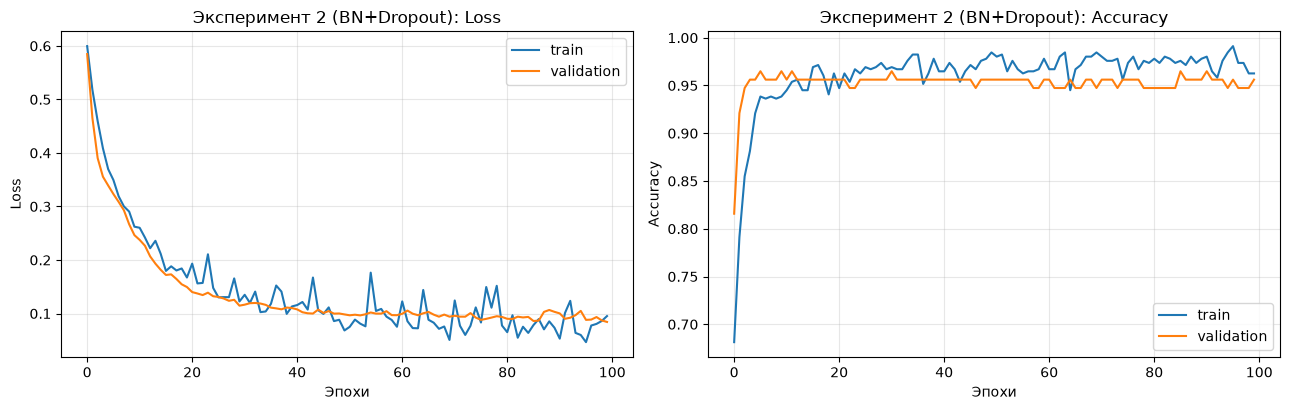

,model,params,train_acc,val_acc,best_val_acc,val_f1,overfit_gap,final_train_loss,final_val_loss
0,"Baseline (16, Adam)",513,0.9846,0.9912,0.9912,0.9930,-0.0066,0.0647,0.0529
1,"Exp1: 64-32, Adam",4097,0.9978,0.9825,0.9912,0.9859,0.0153,0.0077,0.0785
2,"Exp2: BN+Dropout, Adam",4289,0.9626,0.9561,0.9649,0.9650,0.0065,0.0952,0.0843


In [10]:
class RegularizedMLP(nn.Module):
    def __init__(self, input_dim, hidden_1=64, hidden_2=32, p=0.3):
        super(RegularizedMLP, self).__init__()
        self.block1 = nn.Sequential(
            nn.Linear(input_dim, hidden_1),
            nn.BatchNorm1d(hidden_1),
            nn.ReLU(),
            nn.Dropout(p),
        )
        self.block2 = nn.Sequential(
            nn.Linear(hidden_1, hidden_2),
            nn.BatchNorm1d(hidden_2),
            nn.ReLU(),
            nn.Dropout(p),
        )
        self.fc_out = nn.Linear(hidden_2, 1)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        return self.fc_out(x)

set_seed()
reg_model = RegularizedMLP(input_dim=input_size)
reg_criterion = nn.BCEWithLogitsLoss()
reg_optimizer = optim.Adam(reg_model.parameters(), lr=5e-4, weight_decay=1e-4)

reg_history = fit(reg_model, reg_criterion, reg_optimizer, train_loader, test_loader, epochs=100)
plot_history(reg_history, "Эксперимент 2 (BN+Dropout)", "exp2_regularized_curves.png")
results.append(collect_metrics("Exp2: BN+Dropout, Adam", reg_model, reg_history))
pd.DataFrame(results)

### Эксперимент 3 — SGD с импульсом

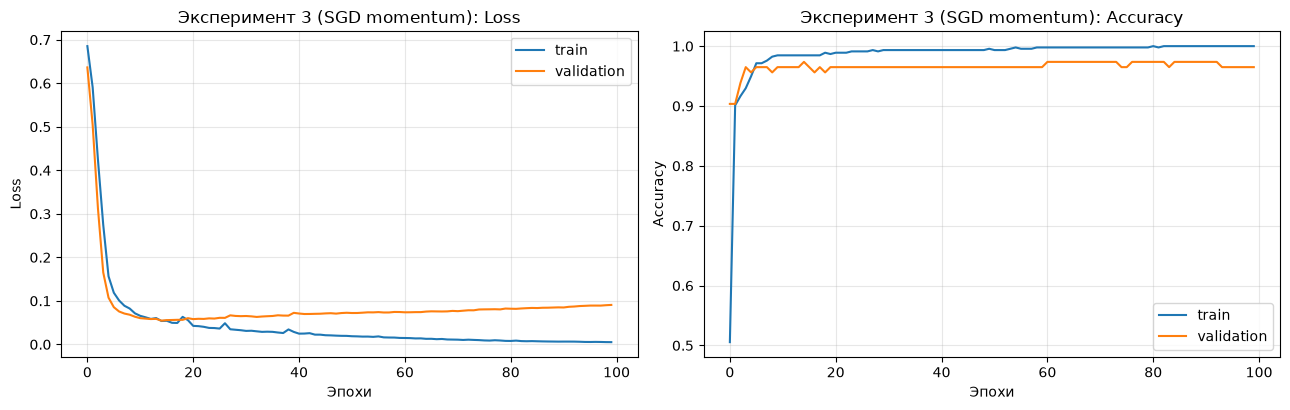

,model,params,train_acc,val_acc,best_val_acc,val_f1,overfit_gap,final_train_loss,final_val_loss
0,"Baseline (16, Adam)",513,0.9846,0.9912,0.9912,0.9930,-0.0066,0.0647,0.0529
1,"Exp1: 64-32, Adam",4097,0.9978,0.9825,0.9912,0.9859,0.0153,0.0077,0.0785
2,"Exp2: BN+Dropout, Adam",4289,0.9626,0.9561,0.9649,0.9650,0.0065,0.0952,0.0843
3,"Exp3: 64-32, SGD+momentum",4097,1.0000,0.9649,0.9737,0.9718,0.0351,0.0051,0.0907


In [11]:
set_seed()
sgd_model = DeepMLP(input_dim=input_size)
sgd_criterion = nn.BCEWithLogitsLoss()
sgd_optimizer = optim.SGD(sgd_model.parameters(), lr=0.01, momentum=0.9)

sgd_history = fit(sgd_model, sgd_criterion, sgd_optimizer, train_loader, test_loader, epochs=100)
plot_history(sgd_history, "Эксперимент 3 (SGD momentum)", "exp3_sgd_curves.png")
results.append(collect_metrics("Exp3: 64-32, SGD+momentum", sgd_model, sgd_history))
pd.DataFrame(results)

### Сводное сравнение моделей

In [12]:
results_df = pd.DataFrame(results)
results_df.to_csv(REPORTS / "model_comparison.csv", index=False)
results_df

,model,params,train_acc,val_acc,best_val_acc,val_f1,overfit_gap,final_train_loss,final_val_loss
0,"Baseline (16, Adam)",513,0.9846,0.9912,0.9912,0.9930,-0.0066,0.0647,0.0529
1,"Exp1: 64-32, Adam",4097,0.9978,0.9825,0.9912,0.9859,0.0153,0.0077,0.0785
2,"Exp2: BN+Dropout, Adam",4289,0.9626,0.9561,0.9649,0.9650,0.0065,0.0952,0.0843
3,"Exp3: 64-32, SGD+momentum",4097,1.0000,0.9649,0.9737,0.9718,0.0351,0.0051,0.0907


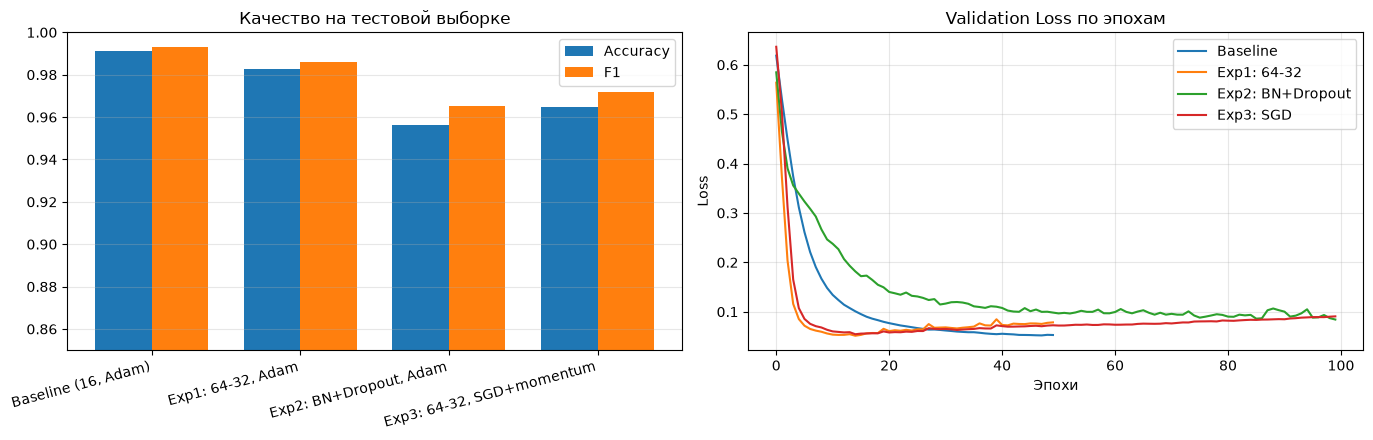

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# accuracy и F1 по моделям
x = np.arange(len(results_df))
width = 0.38
axes[0].bar(x - width / 2, results_df["val_acc"], width, label="Accuracy")
axes[0].bar(x + width / 2, results_df["val_f1"], width, label="F1")
axes[0].set_xticks(x)
axes[0].set_xticklabels(results_df["model"], rotation=15, ha="right")
axes[0].set_ylim(0.85, 1.0)
axes[0].set_title("Качество на тестовой выборке")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend()

# кривые валидационного loss всех моделей
axes[1].plot(baseline_history["val_loss"], label="Baseline")
axes[1].plot(deep_history["val_loss"], label="Exp1: 64-32")
axes[1].plot(reg_history["val_loss"], label="Exp2: BN+Dropout")
axes[1].plot(sgd_history["val_loss"], label="Exp3: SGD")
axes[1].set_title("Validation Loss по эпохам")
axes[1].set_xlabel("Эпохи")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(REPORTS / "models_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

In [14]:
# Матрица ошибок для лучшей по F1 модели
best_name = results_df.loc[results_df["val_f1"].idxmax(), "model"]
models_by_name = {
    "Baseline (16, Adam)": model,
    "Exp1: 64-32, Adam": deep_model,
    "Exp2: BN+Dropout, Adam": reg_model,
    "Exp3: 64-32, SGD+momentum": sgd_model,
}
best_model = models_by_name[best_name]

best_model.eval()
with torch.no_grad():
    out = best_model(torch.tensor(X_test, dtype=torch.float32))
    best_preds = (torch.sigmoid(out) >= 0.5).int().squeeze().numpy()
cm = confusion_matrix(y_test, best_preds)
print("Лучшая модель:", best_name)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

Лучшая модель: Baseline (16, Adam)
Confusion matrix [[TN, FP], [FN, TP]]:
[[42  1]
 [ 0 71]]


## 7. Итоговые выводы

Данные: Breast Cancer, 569 наблюдений, 30 признаков,
разбиение train/test = 455/114 (как в шаблоне: тестовая выборка
используется и для контроля обучения). Все модели обучались с фиксированным seed.

> Важно для интерпретации: в тесте всего 114 объектов, поэтому **одна ошибка
> меняет accuracy на ≈0.9 п.п.** Различия в 1–2 ошибки — статистический шум,
> а не устойчивое преимущество архитектуры.

### 1. Базовая модель

Сеть 30 → 16 → 1 (ReLU, без регуляризации), `BCEWithLogitsLoss`, Adam с lr=1e-3, 50 эпох,
513 параметров.

- accuracy на тесте: **0.9912**, F1: **0.9930**;
- loss: train 0.0647 / val 0.0529;
- разрыв train/val accuracy: **-0.0066**.

Даже такая маленькая сеть почти решает задачу: признаки хорошо разделимы после
стандартизации, а 50 эпох Adam достаточно для сходимости.

### 2. Эксперимент 1 — глубже и шире (30 → 64 → 32 → 1)

Добавлен второй скрытый слой, ширина увеличена до 64 и 32; оптимизатор, lr и число эпох те же,
4097 параметров (в 8 раз больше базовой).

- accuracy: **0.9825** — ниже базовой на 0.87 п.п., F1: **0.9859**;
- разрыв train/val: **+0.0153** (у базовой -0.0066);
- train accuracy 0.9978 при val 0.9825: модель почти запомнила train.

Вывод: на 455 обучающих примерах лишняя ёмкость не помогает — она лишь увеличивает
переобучение и разброс качества.

### 3. Эксперимент 2 — BatchNorm + Dropout + weight decay

Архитектура 64–32 с `BatchNorm1d` после каждого линейного слоя, `Dropout(0.3)`,
`weight_decay=1e-4`, lr=5e-4, 100 эпох.

- accuracy: **0.9561** — ниже базовой на 3.51 п.п., F1: **0.9650**;
- разрыв train/val: **+0.0065**;
- лучшая accuracy по эпохам: 0.9649.

Регуляризация ожидаемо «прижала» train accuracy (0.9626 против 0.9978
у незарегуляризованной широкой сети) и сделала кривые обучения ровнее, но на тесте
итоговое качество не выросло: данных слишком мало, чтобы широкая сеть реализовала
свой потенциал.

### 4. Эксперимент 3 — SGD с импульсом

Архитектура 64–32, `optim.SGD(lr=0.01, momentum=0.9)`, 100 эпох.

- accuracy: **0.9649** — ниже базовой на 2.63 п.п., F1: **0.9718**;
- разрыв train/val: **+0.0351**, train accuracy 1.0000.

SGD с моментом сходится медленнее Adam: к 100-й эпохе train loss минимален
(0.0051), а val loss выше, чем у базовой модели
(0.0907 против 0.0529) — это признак переобучения.

### 5. Самая удачная модель

По F1 на тесте лучшей оказалась **Baseline (16, Adam)** (accuracy 0.9912,
F1 0.9930, разрыв train/val -0.0066).

Это ожидаемый результат для данного датасета: задача почти линейно разделима, а тест
состоит всего из 114 объектов. Простая сеть на 16 нейронов не переобучается
и показывает качество на уровне потолка, тогда как более ёмкие модели тратят её на
запоминание train. Практический вывод: **наращивать архитектуру нужно только после
того, как исчерпаны работа с данными и валидацией**.

Что стоит сделать дальше, чтобы выводы были статистически надёжными:
1. Выделить отдельную валидацию (или использовать `StratifiedKFold` + `cross_val_score`)
   и трогать тест только один раз — сейчас тест одновременно служит валидацией.
2. Подбирать гиперпараметры (lr, dropout, weight decay) по кросс-валидации, а не по одному
   разбиению.
3. Усреднять метрики по нескольким seed'ам: при 114 тестовых объектах разница в одну
   ошибку ничего не значит.


In [15]:
metrics = {
    "baseline": results[0],
    "exp1": results[1],
    "exp2": results[2],
    "exp3": results[3],
    "best": best_name,
    "dataset": {
        "n_samples": int(X.shape[0]),
        "n_features": int(X.shape[1]),
        "train_size": int(X_train.shape[0]),
        "test_size": int(X_test.shape[0]),
    },
}

with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print(json.dumps(metrics, ensure_ascii=False, indent=2))

{
  "baseline": {
    "model": "Baseline (16, Adam)",
    "params": 513,
    "train_acc": 0.9846,
    "val_acc": 0.9912,
    "best_val_acc": 0.9912,
    "val_f1": 0.993,
    "overfit_gap": -0.0066,
    "final_train_loss": 0.0647,
    "final_val_loss": 0.0529
  },
  "exp1": {
    "model": "Exp1: 64-32, Adam",
    "params": 4097,
    "train_acc": 0.9978,
    "val_acc": 0.9825,
    "best_val_acc": 0.9912,
    "val_f1": 0.9859,
    "overfit_gap": 0.0153,
    "final_train_loss": 0.0077,
    "final_val_loss": 0.0785
  },
  "exp2": {
    "model": "Exp2: BN+Dropout, Adam",
    "params": 4289,
    "train_acc": 0.9626,
    "val_acc": 0.9561,
    "best_val_acc": 0.9649,
    "val_f1": 0.965,
    "overfit_gap": 0.0065,
    "final_train_loss": 0.0952,
    "final_val_loss": 0.0843
  },
  "exp3": {
    "model": "Exp3: 64-32, SGD+momentum",
    "params": 4097,
    "train_acc": 1.0,
    "val_acc": 0.9649,
    "best_val_acc": 0.9737,
    "val_f1": 0.9718,
    "overfit_gap": 0.0351,
    "final_train_loss"